# 逻辑回归

在本练习中，你将实现逻辑回归，并把它应用到两个不同的数据集上。


# 目录
- [ 1 - 程序包 ](#1)
- [ 2 - 逻辑回归 ](#2)
  - [ 2.1 问题陈述 ](#2.1)
  - [ 2.2 加载并可视化数据 ](#2.2)
  - [ 2.3  Sigmoid 函数 ](#2.3)
  - [ 2.4 逻辑回归的代价函数 ](#2.4)
  - [ 2.5 逻辑回归的梯度 ](#2.5)
  - [ 2.6 使用梯度下降学习参数 ](#2.6)
  - [ 2.7 绘制决策边界 ](#2.7)
  - [ 2.8 评估逻辑回归 ](#2.8)
- [ 3 - 带正则化的逻辑回归 ](#3)
  - [ 3.1 问题陈述 ](#3.1)
  - [ 3.2 加载并可视化数据 ](#3.2)
  - [ 3.3 特征映射 ](#3.3)
  - [ 3.4 带正则化逻辑回归的代价函数 ](#3.4)
  - [ 3.5 带正则化逻辑回归的梯度 ](#3.5)
  - [ 3.6 使用梯度下降学习参数 ](#3.6)
  - [ 3.7 绘制决策边界 ](#3.7)
  - [ 3.8 评估带正则化的逻辑回归模型 ](#3.8)


<a name="1"></a>
## 1 - 程序包

首先，让我们运行下面的单元格，导入本次作业中需要的所有程序包。
- [numpy](www.numpy.org) 是用 Python 做科学计算的基础程序包。
- [matplotlib](http://matplotlib.org) 是 Python 中著名的绘图库。
-  ``utils.py`` 包含本次作业的辅助函数。你不需要修改该文件中的代码。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
import copy
import math

%matplotlib inline

<a name="2"></a>
## 2 - 逻辑回归

在本练习的这一部分，你将构建一个逻辑回归模型，预测学生能否被大学录取。

<a name="2.1"></a>
### 2.1 问题陈述

假设你是一所大学某系的管理者，你想根据申请者在两门考试中的成绩判断每位申请者的录取机会。
* 你有往届申请者的历史数据，可以作为逻辑回归的训练集。
* 对每个训练样本，你都有申请者在两门考试中的成绩以及录取决定。
* 你的任务是构建一个分类模型，根据这两门考试的成绩估计申请者的录取概率。

<a name="2.2"></a>
### 2.2 加载并可视化数据

你将先加载本任务的数据集。
- 下面所示的 `load_dataset()` 函数把数据加载到变量 `X_train` 和 `y_train` 中
  - `X_train` 包含一名学生在两门考试中的成绩
  - `y_train` 是录取决定
      - 若该学生被录取，`y_train = 1`
      - 若该学生未被录取，`y_train = 0`
  - `X_train` 和 `y_train` 都是 numpy 数组。


In [2]:
# 加载数据集
X_train, y_train = load_data("数据/ex2data1.txt")

#### 查看变量
让我们进一步熟悉你的数据集。
- 一个好的起点就是直接打印每个变量，看看它包含什么。

下面的代码打印 `X_train` 的前五个值和该变量的类型。

In [3]:
print("First five elements in X_train are:\n", X_train[:5])
print("Type of X_train:",type(X_train))

First five elements in X_train are:
 [[34.62365962 78.02469282]
 [30.28671077 43.89499752]
 [35.84740877 72.90219803]
 [60.18259939 86.3085521 ]
 [79.03273605 75.34437644]]
Type of X_train: <class 'numpy.ndarray'>


现在打印 `y_train` 的前五个值

In [4]:
print("First five elements in y_train are:\n", y_train[:5])
print("Type of y_train:",type(y_train))

First five elements in y_train are:
 [0. 0. 0. 1. 1.]
Type of y_train: <class 'numpy.ndarray'>


#### 检查变量的维度

另一种熟悉数据的实用方法是查看其维度。让我们打印 `X_train` 和 `y_train` 的形状，看看数据集中有多少个训练样本。

In [5]:
print ('The shape of X_train is: ' + str(X_train.shape))
print ('The shape of y_train is: ' + str(y_train.shape))
print ('We have m = %d training examples' % (len(y_train)))

The shape of X_train is: (100, 2)
The shape of y_train is: (100,)
We have m = 100 training examples


#### 可视化你的数据

在开始实现任何学习算法之前，如果可能，先可视化数据总是好的。
- 下面的代码把数据展示在二维图中（如下图所示），坐标轴是两门考试的成绩，正样本和负样本用不同标记表示。
- 我们使用 ``utils.py`` 文件中的一个辅助函数来生成这幅图。

<img src="图片/figure 1.png" width="450" height="450">

> **图中文字（中文）**：图例：已录取（Admitted）、未录取（Not admitted） 横轴：考试 1 成绩；纵轴：考试 2 成绩 图 1：训练数据的散点图。



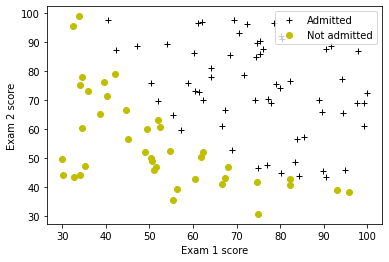

In [6]:
# 绘制样本
plot_data(X_train, y_train[:], pos_label="Admitted", neg_label="Not admitted")

# 设置 y 轴标签
plt.ylabel('Exam 2 score') 
# 设置 x 轴标签
plt.xlabel('Exam 1 score') 
plt.legend(loc="upper right")
plt.show()

你的目标是构建一个逻辑回归模型来拟合这些数据。
- 有了这个模型，你就可以根据一名新学生在两门考试中的成绩预测他是否会被录取。

<a name="2.3"></a>
### 2.3  Sigmoid 函数

回忆一下，对于逻辑回归，模型表示为

$$ f_{\\mathbf{w},b}(x) = g(\\mathbf{w}\\cdot \\mathbf{x} + b)$$
其中函数 $g$ 是 sigmoid 函数。sigmoid 函数定义为：

$$g(z) = \\frac{1}{1+e^{-z}}$$

让我们先实现 sigmoid 函数，以便本次作业的其余部分使用它。

<a name='ex-01'></a>
### 练习 1
请完成 `sigmoid` 函数，以计算

$$g(z) = \\frac{1}{1+e^{-z}}$$

注意
- `z` 并不总是一个数字，也可能是数字数组。
- 如果输入是数字数组，我们要对输入数组中的每个值应用 sigmoid 函数。

如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [11]:
# UNQ_C1
# 计分函数：sigmoid

def sigmoid(z):
    """计算 z 的 sigmoid

    参数：
        z (ndarray): 标量，或任意大小的 numpy 数组。

    返回：
        g (ndarray): sigmoid(z)，形状与 z 相同"""
          
    ### 在此处编写代码 ###

    ### 解答结束 ###
    
    return g

<details>
  <summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>
       
`numpy` 有一个名为 [`np.exp()`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html) 的函数，它提供了一种便捷的方法来计算输入数组（`z`）中所有元素的指数（$e^{z}$）。

<details>
          <summary><font size="2" color="darkblue"><b> 点击查看更多提示</b></font></summary>
        
  - 你可以把 $e^{-z}$ 写成代码 `np.exp(-z)`
    
  - 你可以把 $1/e^{-z}$ 写成代码 `1/np.exp(-z)`
    
    如果仍然卡住，可以查看下面的提示，弄清如何计算 `g`
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 g 的提示</b></font></summary>
        <code>g = 1 / (1 + np.exp(-z))</code>
    </details>


</details>

完成后，请在下面的单元格中调用 `sigmoid(x)` 测试几个值。
- 当 x 取很大的正值时，sigmoid 应接近 1；当 x 取很大的负值时，sigmoid 应接近 0。
- 计算 `sigmoid(0)` 应恰好得到 0.5。


In [12]:
print ("sigmoid(0) = " + str(sigmoid(0)))

sigmoid(0) = 0.5


**预期输出**：
<table>
  <tr>
    <td> <b>sigmoid(0)<b></td>
    <td> 0.5 </td> 
  </tr>
</table>
    
- 如前所述，你的代码也应能处理向量和矩阵。对于矩阵，你的函数应对每个元素执行 sigmoid 运算。

In [13]:
print ("sigmoid([ -1, 0, 1, 2]) = " + str(sigmoid(np.array([-1, 0, 1, 2]))))

# 单元测试
from public_tests import *
sigmoid_test(sigmoid)

sigmoid([ -1, 0, 1, 2]) = [0.26894142 0.5        0.73105858 0.88079708]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td><b>sigmoid([-1, 0, 1, 2])<b></td> 
    <td>[0.26894142        0.5           0.73105858        0.88079708]</td> 
  </tr>    
  
</table>

<a name="2.4"></a>
### 2.4 逻辑回归的代价函数

本节中，你将实现逻辑回归的代价函数。

<a name='ex-02'></a>
### 练习 2

请使用下面的方程完成 `compute_cost` 函数。

回忆一下，对于逻辑回归，代价函数的形式为

$$ J(\\mathbf{w},b) = \\frac{1}{m}\\sum_{i=0}^{m-1} \\left[ loss(f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}), y^{(i)}) \\right] \\tag{1}$$

其中
* m 是数据集中的训练样本数


* $loss(f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}), y^{(i)})$ 是单个数据点的代价，即 -

    $$loss(f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}), y^{(i)}) = (-y^{(i)} \\log\\left(f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right) - \\left( 1 - y^{(i)}\\right) \\log \\left( 1 - f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right) \\tag{2}$$
    
    
*  $f_{\\mathbf{w},b}(\\mathbf{x}^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是实际标签

*  $f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) = g(\\mathbf{w} \\cdot \\mathbf{x^{(i)}} + b)$，其中函数 $g$ 是 sigmoid 函数。
    * 先计算中间变量 $z_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) = \\mathbf{w} \\cdot \\mathbf{x^{(i)}} + b = w_0x^{(i)}_0 + ... + w_{n-1}x^{(i)}_{n-1} + b$ 可能更有帮助（其中 $n$ 是特征数），然后再计算 $f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) = g(z_{\\mathbf{w},b}(\\mathbf{x}^{(i)}))$

注意：
* 在做这件事时请记住，变量 `X_train` 和 `y_train` 不是标量值，而是形状分别为 ($m, n$) 和 ($𝑚$,1) 的矩阵，其中 $𝑛$ 是特征数，$𝑚$ 是训练样本数。
* 本部分你可以使用上面实现的 sigmoid 函数。

如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [14]:
# UNQ_C2
# 计分函数：compute_cost
def compute_cost(X, y, w, b, lambda_= 1):
    """计算所有样本上的代价
    参数：
      X : (ndarray 形状 (m,n)) 数据，m 个样本，n 个特征
      y : (array_like 形状 (m,)) 目标值
      w : (array_like 形状 (n,)) 模型参数取值
      b : scalar 模型偏置参数取值
      lambda_: 未使用的占位参数
    返回：
      total_cost: (scalar)         代价"""

    m, n = X.shape
    
    ### 在此处编写代码 ###

    ### 代码编写结束 ###

    return total_cost

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 你可以用代码表示求和运算符，例如 $h = \\sum\\limits_{i = 0}^{m-1} 2i$：

```python 
    h = 0
    for i in range(m):
        h = h + 2*i
```


* 在这个例子中，你可以用 for 循环遍历 <code>X</code> 中的所有样本，并把每次迭代的 <code>loss</code> 累加到循环外初始化的变量（<code>loss_sum</code>）中。

* 然后，你可以返回 <code>total_cost</code>，即 <code>loss_sum</code> 除以 <code>m</code>。

<details>
      <summary><font size="2" color="darkblue"><b> 点击查看更多提示</b></font></summary>

* 下面是这个函数整体实现的结构

```python 
def compute_cost(X, y, w, b, lambda_= 1):
    m, n = X.shape

    ### START CODE HERE ###
    loss_sum = 0 

    # Loop over each training example
    for i in range(m): 

        # First calculate z_wb = w[0]*X[i][0]+...+w[n-1]*X[i][n-1]+b
        z_wb = 0 
        # Loop over each feature
        for j in range(n): 
            # Add the corresponding term to z_wb
            z_wb_ij = # Your code here to calculate w[j] * X[i][j]
            z_wb += z_wb_ij # equivalent to z_wb = z_wb + z_wb_ij
        # Add the bias term to z_wb
        z_wb += b # equivalent to z_wb = z_wb + b

        f_wb = # Your code here to calculate prediction f_wb for a training example
        loss =  # Your code here to calculate loss for a training example

        loss_sum += loss # equivalent to loss_sum = loss_sum + loss

    total_cost = (1 / m) * loss_sum  
    ### END CODE HERE ### 

    return total_cost
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 <code>z_wb_ij</code>、<code>f_wb</code> 和 <code>cost</code>。
<details>
      <summary><font size="2" color="darkblue"><b>计算 z_wb_ij 的提示</b></font></summary>
       &emsp; &emsp; <code>z_wb_ij = w[j]*X[i][j] </code>
</details>

<details>
      <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
       &emsp; &emsp; $f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) = g(z_{\\mathbf{w},b}(\\mathbf{x}^{(i)}))$，其中 $g$ 是 sigmoid 函数。你可以直接调用上面实现的 <code>sigmoid</code> 函数。
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f 的更多提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 f_wb：<code>f_wb = sigmoid(z_wb) </code>
       </details>
</details>

 <details>
      <summary><font size="2" color="darkblue"><b>计算 loss 的提示</b></font></summary>
      &emsp; &emsp; 你可以使用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.log.html">np.log</a> 函数来计算对数
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 loss 的更多提示</b></font></summary>
          &emsp; &emsp; 你可以这样计算 loss：<code>loss =  -y[i] * np.log(f_wb) - (1 - y[i]) * np.log(1 - f_wb)</code>
      </details>
</details>

</details>

</details>

运行下面的单元格，用两组不同的参数初始化 $w$ 来检查你对 `compute_cost` 函数的实现

In [15]:
m, n = X_train.shape

# 在 w 初始化为零的情况下计算并显示代价
initial_w = np.zeros(n)
initial_b = 0.
cost = compute_cost(X_train, y_train, initial_w, initial_b)
print('Cost at initial w (zeros): {:.3f}'.format(cost))

Cost at initial w (zeros): 0.693


**预期输出**：
<table>
  <tr>
    <td> <b>初始 w（全零）时的代价<b></td>
    <td> 0.693 </td> 
  </tr>
</table>

In [16]:
# 在 w 非零的情况下计算并显示代价
test_w = np.array([0.2, 0.2])
test_b = -24.
cost = compute_cost(X_train, y_train, test_w, test_b)

print('Cost at test w,b: {:.3f}'.format(cost))


# 单元测试
compute_cost_test(compute_cost)


Cost at test w,b: 0.219


AssertionError: Wrong output. Expected: 2.15510667 got: 2.75932426268233

**预期输出**：
<table>
  <tr>
    <td> <b>测试 w,b 处的代价<b></td>
    <td> 0.218 </td> 
  </tr>
</table>

<a name="2.5"></a>
### 2.5 逻辑回归的梯度

本节中，你将实现逻辑回归的梯度。

回忆一下，梯度下降算法为：

$$\\begin{align*}& \\text{repeat until convergence:} \\; \\lbrace \\newline \\; & b := b -  \\alpha \\frac{\\partial J(\\mathbf{w},b)}{\\partial b} \\newline       \\; & w_j := w_j -  \\alpha \\frac{\\partial J(\\mathbf{w},b)}{\\partial w_j} \\tag{1}  \\; & \\text{for j := 0..n-1}\\newline & \\rbrace\\end{align*}$$

其中参数 $b$、$w_j$ 都是同时更新的


<a name='ex-03'></a>
### 练习 3

请完成 `compute_gradient` 函数，根据下面的公式 (2) 和 (3) 计算 $\\frac{\\partial J(\\mathbf{w},b)}{\\partial w}$、$\\frac{\\partial J(\\mathbf{w},b)}{\\partial b}$。

$$
\\frac{\\partial J(\\mathbf{w},b)}{\\partial b}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - \\mathbf{y}^{(i)}) \\tag{2}
$$
$$
\\frac{\\partial J(\\mathbf{w},b)}{\\partial w_j}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - \\mathbf{y}^{(i)})x_{j}^{(i)} \\tag{3}
$$
* m 是数据集中的训练样本数

    
*  $f_{\\mathbf{w},b}(x^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是实际标签


- **注意**：虽然这个梯度看起来与线性回归的梯度相同，但公式实际上是不同的，因为线性回归和逻辑回归对 $f_{\\mathbf{w},b}(x)$ 的定义不同。

和之前一样，你可以使用上面实现的 sigmoid 函数；如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [ ]:
# UNQ_C3
# 计分函数：compute_gradient
def compute_gradient(X, y, w, b, lambda_=None): 
    """计算逻辑回归的梯度
 
    参数：
      X : (ndarray 形状 (m,n)) 变量，例如房屋面积
      y : (array_like 形状 (m,1)) 实际值
      w : (array_like 形状 (n,1)) 模型参数取值
      b : (scalar)                模型参数取值
      lambda_: 未使用的占位参数。
    返回
      dj_dw: (array_like 形状 (n,1)) 代价对参数 w 的梯度。
      dj_db: (scalar)                代价对参数 b 的梯度。"""
    m, n = X.shape
    dj_dw = np.zeros(w.shape)
    dj_db = 0.

    ### 在此处编写代码 ###

    ### 代码编写结束 ###

        
    return dj_db, dj_dw

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 下面是这个函数整体实现的结构

```python 
   def compute_gradient(X, y, w, b, lambda_=None): 
        m, n = X.shape
        dj_dw = np.zeros(w.shape)
        dj_db = 0.

        ### START CODE HERE ### 
        err  = 0.
        for i in range(m):
            # Calculate f_wb (exactly as you did in the compute_cost function above)
            f_wb = 

            # Calculate the  gradient for b from this example
            dj_db_i = # Your code here to calculate the error

            # add that to dj_db
            dj_db += dj_db_i

            # get dj_dw for each attribute
            for j in range(n):
                # You code here to calculate the gradient from the i-th example for j-th attribute
                dj_dw_ij =  
                dj_dw[j] += dj_dw_ij

        # divide dj_db and dj_dw by total number of examples
        dj_dw = dj_dw / m
        dj_db = dj_db / m
        ### END CODE HERE ###

        return dj_db, dj_dw
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `f_wb`、`dj_db_i` 和 `dj_dw_ij`

<details>
      <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
       &emsp; &emsp; 回忆一下，你在上面的 <code>compute_cost</code> 中计算过 f_wb —— 关于如何计算各个中间项的详细提示，请看该练习下方的提示部分
       <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f_wb 的更多提示</b></font></summary>
          &emsp; &emsp; 你可以这样计算 f_wb
           <pre>
           for i in range(m):   
               # 计算 f_wb（与你上面 compute_cost 函数中的做法完全一样）
               z_wb = 0
               # 遍历每个特征
               for j in range(n): 
                   # 把对应项加到 z_wb
                   z_wb_ij = X[i, j] * w[j]
                   z_wb += z_wb_ij

               # 加上偏置项
               z_wb += b

               # 计算模型的预测
               f_wb = sigmoid(z_wb)
</details>

</details>
<details>
      <summary><font size="2" color="darkblue"><b>计算 dj_db_i 的提示</b></font></summary>
       &emsp; &emsp; 你可以这样计算 dj_db_i：<code>dj_db_i = f_wb - y[i]</code>
</details>

<details>
      <summary><font size="2" color="darkblue"><b>计算 dj_dw_ij 的提示</b></font></summary>
    &emsp; &emsp; 你可以这样计算 dj_dw_ij：<code>dj_dw_ij = (f_wb - y[i])* X[i][j]</code>
</details>

</details>

运行下面的单元格，用两组不同的参数初始化 $w$ 来检查你对 `compute_gradient` 函数的实现

In [ ]:
# 在 w 初始化为零的情况下计算并显示梯度
initial_w = np.zeros(n)
initial_b = 0.

dj_db, dj_dw = compute_gradient(X_train, y_train, initial_w, initial_b)
print(f'dj_db at initial w (zeros):{dj_db}' )
print(f'dj_dw at initial w (zeros):{dj_dw.tolist()}' )

**预期输出**：
<table>
  <tr>
    <td> <b>初始 w（全零）处的 dj_db<b></td>
    <td> -0.1 </td> 
  </tr>
  <tr>
    <td> <b>初始 w（全零）处的 dj_dw：<b></td>
    <td> [-12.00921658929115, -11.262842205513591] </td> 
  </tr>
</table>

In [ ]:
# 在 w 非零的情况下计算并显示代价和梯度
test_w = np.array([ 0.2, -0.5])
test_b = -24
dj_db, dj_dw  = compute_gradient(X_train, y_train, test_w, test_b)

print('dj_db at test_w:', dj_db)
print('dj_dw at test_w:', dj_dw.tolist())

# 单元测试
compute_gradient_test(compute_gradient)


**预期输出**：
<table>
  <tr>
    <td> <b>初始 w（全零）处的 dj_db<b></td>
    <td> -0.5999999999991071 </td> 
  </tr>
  <tr>
    <td> <b>初始 w（全零）处的 dj_dw：<b></td>
    <td>  [-44.8313536178737957, -44.37384124953978] </td> 
  </tr>
</table>

<a name="2.6"></a>
### 2.6 使用梯度下降学习参数

与上一次作业类似，你现在将使用梯度下降找到逻辑回归模型的最优参数。
- 这一部分你不需要实现任何内容，只需运行下面的单元格。

- 验证梯度下降是否正确工作的一个好方法是查看 $J(\\mathbf{w},b)$ 的值，检查它是否每一步都在减小。

- 假设你正确实现了梯度并正确计算了代价，那么 $J(\\mathbf{w},b)$ 应该从不增大，并在算法结束时收敛到一个稳定值。

In [ ]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters, lambda_): 
    """执行批量梯度下降以学习 theta。以学习率 alpha 走
    num_iters 个梯度步来更新 theta
   
    参数：
      X :    (array_like 形状 (m, n)
      y :    (array_like 形状 (m,))
      w_in : (array_like 形状 (n,))  模型参数的初始值
      b_in : (scalar)                 模型参数的初始值
      cost_function:                  用于计算代价的函数
      alpha : (float)                 学习率
      num_iters : (int)               运行梯度下降的迭代次数
      lambda_ (scalar, float)         正则化常数
     
    返回：
      w : (array_like 形状 (n,)) 运行梯度下降后更新得到的模型参数值
      b : (scalar)                运行梯度下降后更新得到的模型参数值"""
    
    # 训练样本数
    m = len(X)
    
    # 用于存放代价 J 以及每次迭代的 w，主要供后续绘图使用
    J_history = []
    w_history = []
    
    for i in range(num_iters):

        # 计算梯度并更新参数
        dj_db, dj_dw = gradient_function(X, y, w_in, b_in, lambda_)   

        # 用 w、b、alpha 和梯度更新参数
        w_in = w_in - alpha * dj_dw               
        b_in = b_in - alpha * dj_db              
       
        # 每次迭代保存代价 J
        if i<100000:      # 防止资源耗尽
            cost =  cost_function(X, y, w_in, b_in, lambda_)
            J_history.append(cost)

        # 每 10 次迭代打印一次代价；若迭代次数少于 10，则打印所有迭代
        if i% math.ceil(num_iters/10) == 0 or i == (num_iters-1):
            w_history.append(w_in)
            print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}   ")
        
    return w_in, b_in, J_history, w_history #返回 w 以及用于绘图的 J、w 历史

现在让我们运行上面的梯度下降算法来学习数据集对应的参数。

**注意**

下面的代码块要运行几分钟，尤其是非向量化版本。你可以减少 `iterations` 来测试你的实现并更快迭代。如果有时间，可以尝试运行 100,000 次迭代以获得更好的结果。

In [ ]:
np.random.seed(1)
intial_w = 0.01 * (np.random.rand(2).reshape(-1,1) - 0.5)
initial_b = -8


# 一些梯度下降设置
iterations = 10000
alpha = 0.001

w,b, J_history,_ = gradient_descent(X_train ,y_train, initial_w, initial_b, 
                                   compute_cost, compute_gradient, alpha, iterations, 0)

<details>
<summary>
    <b>预期输出：代价 0.30（点击查看详细信息）：</b>
</summary>

    # 使用以下设置
    np.random.seed(1)
    intial_w = 0.01 * (np.random.rand(2).reshape(-1,1) - 0.5)
    initial_b = -8
    iterations = 10000
    alpha = 0.001
    #


```
Iteration    0: Cost     1.01   
Iteration 1000: Cost     0.31   
Iteration 2000: Cost     0.30   
Iteration 3000: Cost     0.30   
Iteration 4000: Cost     0.30   
Iteration 5000: Cost     0.30   
Iteration 6000: Cost     0.30   
Iteration 7000: Cost     0.30   
Iteration 8000: Cost     0.30   
Iteration 9000: Cost     0.30   
Iteration 9999: Cost     0.30   
```


<a name="2.7"></a>
### 2.7 绘制决策边界

我们现在将使用梯度下降得到的最终参数来绘制线性拟合。如果你正确实现了前面各部分，应该会看到下面的图：   
<img src="图片/figure 2.png"  width="450" height="450">

> **图中文字（中文）**：横轴：考试 1 成绩；纵轴：考试 2 成绩；图例：已录取、未录取 图 2：带决策边界的训练数据。

我们将使用 `utils.py` 文件中的一个辅助函数来创建这幅图。

In [ ]:
plot_decision_boundary(w, b, X_train, y_train)

<a name="2.8"></a>
### 2.8 评估逻辑回归

我们可以通过观察学习到的模型在训练集上的预测效果，来评估所找到参数的质量。

你将实现下面的 `predict` 函数来完成这件事。


<a name='ex-04'></a>
### 练习 4

请完成 `predict` 函数，在给定数据集以及学习到的参数向量 $w$ 和 $b$ 的情况下，输出 `1` 或 `0` 的预测。
- 首先你需要对每个样本计算模型的预测 $f(x^{(i)}) = g(w \\cdot x^{(i)})$
    - 你在上面的部分中已经实现过这一点
- 我们把模型的输出（$f(x^{(i)})$）解释为在给定 $x^{(i)}$、并以 $w$ 为参数时 $y^{(i)}=1$ 的概率。
- 因此，要从逻辑回归模型得到最终预测（$y^{(i)}=0$ 或 $y^{(i)}=1$），你可以使用下面的启发式规则——

  若 $f(x^{(i)}) >= 0.5$，预测 $y^{(i)}=1$
  
  若 $f(x^{(i)}) < 0.5$，预测 $y^{(i)}=0$
    
如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [ ]:
# UNQ_C4
# 计分函数：predict

def predict(X, w, b): 
    """使用学习到的逻辑回归参数 w 预测标签是 0 还是 1
   
    参数：
    X : (ndarray 形状 (m, n))
    w : (array_like 形状 (n,))      模型参数
    b : (scalar, float)             模型参数

    返回：
    p: (ndarray (m,1))
        以 0.5 为阈值对 X 做出的预测"""
    # 训练样本数
    m, n = X.shape   
    p = np.zeros(m)
   
    ### 在此处编写代码 ###
        
    ### 代码编写结束 ###
    return p

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 下面是这个函数整体实现的结构

```python 
   def predict(X, w, b): 
        # number of training examples
        m, n = X.shape   
        p = np.zeros(m)

        ### START CODE HERE ### 
        # Loop over each example
        for i in range(m):   

            # Calculate f_wb (exactly how you did it in the compute_cost function above) 
            # using a couple of lines of code
            f_wb = 

            # Calculate the prediction for that training example 
            p[i] = # Your code here to calculate the prediction based on f_wb

        ### END CODE HERE ### 
        return p
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `f_wb` 和 `p[i]`

<details>
      <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
       &emsp; &emsp; 回忆一下，你在上面的 <code>compute_cost</code> 中计算过 f_wb —— 关于如何计算各个中间项的详细提示，请看该练习下方的提示部分
       <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f_wb 的更多提示</b></font></summary>
          &emsp; &emsp; 你可以这样计算 f_wb
           <pre>
           for i in range(m):   
               # 计算 f_wb（与你上面 compute_cost 函数中的做法完全一样）
               z_wb = 0
               # 遍历每个特征
               for j in range(n): 
                   # 把对应项加到 z_wb
                   z_wb_ij = X[i, j] * w[j]
                   z_wb += z_wb_ij

               # 加上偏置项
               z_wb += b

               # 计算模型的预测
               f_wb = sigmoid(z_wb)
</details>

</details>
<details>
      <summary><font size="2" color="darkblue"><b>计算 p[i] 的提示</b></font></summary>
       &emsp; &emsp; 举例来说，如果你想表达“当 y 小于 3 时 x = 1，否则为 0”，可以在代码中写成 <code>x = y < 3 </code>。现在对 p[i] 做同样的事：当 f_wb >= 0.5 时 p[i] = 1，否则为 0。
       <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 p[i] 的更多提示</b></font></summary>
          &emsp; &emsp; 你可以这样计算 p[i]：<code>p[i] = f_wb >= 0.5</code>
      </details>
</details>

</details>

完成 `predict` 函数后，让我们运行下面的代码，通过计算分类器预测正确的样本百分比来报告其训练准确率。

In [ ]:
# 测试你的 predict 代码
np.random.seed(1)
tmp_w = np.random.randn(2)
tmp_b = 0.3    
tmp_X = np.random.randn(4, 2) - 0.5

tmp_p = predict(tmp_X, tmp_w, tmp_b)
print(f'Output of predict: shape {tmp_p.shape}, value {tmp_p}')

# 单元测试
predict_test(predict)

**预期输出**

<table>
  <tr>
    <td> <b>predict 的输出：形状 (4,)，值 [0. 1. 1. 1.]<b></td>
  </tr>
</table>

现在让我们用它来计算训练集上的准确率

In [ ]:
#计算在训练集上的准确率
p = predict(X_train, w,b)
print('Train Accuracy: %f'%(np.mean(p == y_train) * 100))

<table>
  <tr>
    <td> <b>训练准确率（约）：<b></td>
    <td> 92.00 </td> 
  </tr>
</table>

<a name="3"></a>
## 3 - 带正则化的逻辑回归

在本练习的这一部分，你将实现带正则化的逻辑回归，以预测某制造厂的微芯片是否通过质量保证（QA）。在 QA 过程中，每块微芯片都要经过多项测试，以确保其功能正常。

<a name="3.1"></a>
### 3.1 问题陈述

假设你是这家工厂的产品经理，你有若干微芯片在两项不同测试中的结果。
- 根据这两项测试，你想判断这些微芯片应当被接受还是被拒绝。
- 为了帮你做决定，你有一份以往微芯片测试结果的数据集，可以用它构建一个逻辑回归模型。

<a name="3.2"></a>
### 3.2 加载并可视化数据

与本练习前面的部分类似，让我们先加载本任务的数据集并可视化。

- 下面所示的 `load_dataset()` 函数把数据加载到变量 `X_train` 和 `y_train` 中
  - `X_train` 包含微芯片在两项测试中的结果
  - `y_train` 包含 QA 的结果
      - 若微芯片被接受，`y_train = 1`
      - 若微芯片被拒绝，`y_train = 0`
  - `X_train` 和 `y_train` 都是 numpy 数组。

In [ ]:
# 加载数据集
X_train, y_train = load_data("数据/ex2data2.txt")

#### 查看变量

下面的代码打印 `X_train` 和 `y_train` 的前五个值以及变量的类型。


In [ ]:
# 打印 X_train
print("X_train:", X_train[:5])
print("Type of X_train:",type(X_train))

# 打印 y_train
print("y_train:", y_train[:5])
print("Type of y_train:",type(y_train))

#### 检查变量的维度

另一种熟悉数据的实用方法是查看其维度。让我们打印 `X_train` 和 `y_train` 的形状，看看数据集中有多少个训练样本。

In [ ]:
print ('The shape of X_train is: ' + str(X_train.shape))
print ('The shape of y_train is: ' + str(y_train.shape))
print ('We have m = %d training examples' % (len(y_train)))

#### 可视化你的数据

辅助函数 `plot_data`（来自 `utils.py`）用于生成类似图 3 的图形，其中坐标轴是两项测试的成绩，正样本（y = 1，被接受）和负样本（y = 0，被拒绝）用不同标记表示。

<img src="图片/figure 3.png"  width="450" height="450">

> **图中文字（中文）**：横轴：微芯片测试 1；纵轴：微芯片测试 2 图 3：训练数据的散点图。

In [ ]:
# 绘制样本
plot_data(X_train, y_train[:], pos_label="Accepted", neg_label="Rejected")

# 设置 y 轴标签
plt.ylabel('Microchip Test 2') 
# 设置 x 轴标签
plt.xlabel('Microchip Test 1') 
plt.legend(loc="upper right")
plt.show()

图 3 表明，我们的数据集无法用图中的一条直线把正样本和负样本分开。因此，直接套用逻辑回归在这个数据集上表现不会好，因为逻辑回归只能找到线性的决策边界。


<a name="3.3"></a>
### 3.3 特征映射

更好地拟合数据的一种办法是从每个数据点构造出更多特征。在提供的 `map_feature` 函数中，我们会把特征映射为 $x_1$ 和 $x_2$ 的所有多项式项，直到六次幂。

$$\\mathrm{map\\_feature}(x) = 
\\left[\\begin{array}{c}
x_1\\\\
x_2\\\\
x_1^2\\\\
x_1 x_2\\\\
x_2^2\\\\
x_1^3\\\\
\\vdots\\\\
x_1 x_2^5\\\\
x_2^6\\end{array}\\right]$$

经过这一映射，我们原本由两个特征（两项 QA 测试的成绩）组成的向量被转换成了 27 维向量。

- 在这个更高维的特征向量上训练的逻辑回归分类器会具有更复杂的决策边界，在我们二维图中画出来将是非线性的。
- 我们已在 utils.py 中为你提供了 `map_feature` 函数。

In [ ]:
print("Original shape of data:", X_train.shape)

mapped_X =  map_feature(X_train[:, 0], X_train[:, 1])
print("Shape after feature mapping:", mapped_X.shape)

让我们也打印 `X_train` 和 `mapped_X` 的前几个元素，看看这一变换。

In [ ]:
print("X_train[0]:", X_train[0])
print("mapped X_train[0]:", mapped_X[0])

特征映射虽然让我们能构建表达能力更强的分类器，但也更容易过拟合。在本练习接下来的部分中，你将实现带正则化的逻辑回归来拟合数据，并亲眼看看正则化如何帮助应对过拟合问题。

<a name="3.4"></a>
### 3.4 带正则化逻辑回归的代价函数

在这部分，你将实现带正则化逻辑回归的代价函数。

回忆一下，对于带正则化的逻辑回归，代价函数的形式为
$$J(\\mathbf{w},b) = \\frac{1}{m}  \\sum_{i=0}^{m-1} \\left[ -y^{(i)} \\log\\left(f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right) - \\left( 1 - y^{(i)}\\right) \\log \\left( 1 - f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right) \\right] + \\frac{\\lambda}{2m}  \\sum_{j=0}^{n-1} w_j^2$$

把它与不带正则化的代价函数（你在上面实现过）比较，后者形式为

$$ J(\\mathbf{w}.b) = \\frac{1}{m}\\sum_{i=0}^{m-1} \\left[ (-y^{(i)} \\log\\left(f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right) - \\left( 1 - y^{(i)}\\right) \\log \\left( 1 - f_{\\mathbf{w},b}\\left( \\mathbf{x}^{(i)} \\right) \\right)\\right]$$

区别在于正则化项，即 $$\\frac{\\lambda}{2m}  \\sum_{j=0}^{n-1} w_j^2$$ 
注意，参数 $b$ 不做正则化。

<a name='ex-05'></a>
### 练习 5

请完成下面的 `compute_cost_reg` 函数，对 $w$ 中的每个元素计算下面这一项
$$\\frac{\\lambda}{2m}  \\sum_{j=0}^{n-1} w_j^2$$

起始代码随后会把它加到不带正则化的代价上（你在上面的 `compute_cost` 中计算过），从而得到带正则化的代价。

如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [ ]:
# UNQ_C5
def compute_cost_reg(X, y, w, b, lambda_ = 1):
    """计算所有样本上的代价
    参数：
      X : (array_like 形状 (m,n)) 数据，m 个样本，n 个特征
      y : (array_like 形状 (m,)) 目标值
      w : (array_like 形状 (n,)) 模型参数取值
      b : (array_like 形状 (n,)) 模型偏置参数取值
      lambda_ : (scalar, float)    控制正则化强度
    返回：
      total_cost: (scalar)         代价"""

    m, n = X.shape
    
    # 调用你上面实现的 compute_cost 函数
    cost_without_reg = compute_cost(X, y, w, b) 
    
    # 你需要计算这个值
    reg_cost = 0.
    
    ### 在此处编写代码 ###
    
        
    ### 代码编写结束 ###
    
    # 把正则化代价加上去得到总代价
    total_cost = cost_without_reg + (lambda_/(2 * m)) * reg_cost

    return total_cost

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 下面是这个函数整体实现的结构

```python 
   def compute_cost_reg(X, y, w, b, lambda_ = 1):

       m, n = X.shape

        # Calls the compute_cost function that you implemented above
        cost_without_reg = compute_cost(X, y, w, b) 

        # You need to calculate this value
        reg_cost = 0.

        ### START CODE HERE ###
        for j in range(n):
            reg_cost_j = # Your code here to calculate the cost from w[j]
            reg_cost = reg_cost + reg_cost_j

        ### END CODE HERE ### 

        # Add the regularization cost to get the total cost
        total_cost = cost_without_reg + (lambda_/(2 * m)) * reg_cost

    return total_cost
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `reg_cost_j`

<details>
      <summary><font size="2" color="darkblue"><b>计算 reg_cost_j 的提示</b></font></summary>
       &emsp; &emsp; 你可以这样计算 reg_cost_j：<code>reg_cost_j = w[j]**2 </code> 
</details>

</details>

</details>



运行下面的单元格，检查你对 `compute_cost_reg` 函数的实现。

In [ ]:
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1]) - 0.5
initial_b = 0.5
lambda_ = 0.5
cost = compute_cost_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print("Regularized cost :", cost)

# 单元测试
compute_cost_reg_test(compute_cost_reg)


**预期输出**：
<table>
  <tr>
    <td> <b>正则化代价： <b></td>
    <td> 0.6618252552483948 </td> 
  </tr>
</table>

<a name="3.5"></a>
### 3.5 带正则化逻辑回归的梯度

本节中，你将实现带正则化逻辑回归的梯度。


带正则化代价函数的梯度有两个部分。第一个是 $\\frac{\\partial J(\\mathbf{w},b)}{\\partial b}$，为标量；另一个是与参数 $\\mathbf{w}$ 形状相同的向量，其第 $j^\\mathrm{th}$ 个元素定义如下：

$$\\frac{\\partial J(\\mathbf{w},b)}{\\partial b} = \\frac{1}{m}  \\sum_{i=0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - y^{(i)})  $$

$$\\frac{\\partial J(\\mathbf{w},b)}{\\partial w_j} = \\left( \\frac{1}{m}  \\sum_{i=0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - y^{(i)}) x_j^{(i)} \\right) + \\frac{\\lambda}{m} w_j  \\quad\\, \\mbox{for $j=0...(n-1)$}$$

把它与不带正则化代价函数的梯度（你在上面实现过）比较，后者形式为
$$
\\frac{\\partial J(\\mathbf{w},b)}{\\partial b}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - \\mathbf{y}^{(i)}) \\tag{2}
$$
$$
\\frac{\\partial J(\\mathbf{w},b)}{\\partial w_j}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{\\mathbf{w},b}(\\mathbf{x}^{(i)}) - \\mathbf{y}^{(i)})x_{j}^{(i)} \\tag{3}
$$


可以看到，$\\frac{\\partial J(\\mathbf{w},b)}{\\partial b}$ 是相同的，区别在于 $\\frac{\\partial J(\\mathbf{w},b)}{\\partial w}$ 中的下面这一项，即 $$\\frac{\\lambda}{m} w_j  \\quad\\, \\mbox{for $j=0...(n-1)$}$$ 





<a name='ex-06'></a>
### 练习 6

请完成下面的 `compute_gradient_reg` 函数，修改下面的代码以计算下面这一项

$$\\frac{\\lambda}{m} w_j  \\quad\\, \\mbox{for $j=0...(n-1)$}$$

起始代码会把这一项加到上面 `compute_gradient` 返回的 $\\frac{\\partial J(\\mathbf{w},b)}{\\partial w}$ 上，从而得到带正则化代价函数的梯度。


如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [ ]:
# UNQ_C6
def compute_gradient_reg(X, y, w, b, lambda_ = 1): 
    """计算线性回归的梯度
 
    参数：
      X : (ndarray 形状 (m,n))   变量，例如房屋面积
      y : (ndarray 形状 (m,))    实际值
      w : (ndarray 形状 (n,))    模型参数取值
      b : (scalar)                模型参数取值
      lambda_ : (scalar,float)    正则化常数
    返回
      dj_db: (scalar)             代价对参数 b 的梯度。
      dj_dw: (ndarray 形状 (n,)) 代价对参数 w 的梯度。"""
    m, n = X.shape
    
    dj_db, dj_dw = compute_gradient(X, y, w, b)

    ### 在此处编写代码 ###
    
        
    ### 代码编写结束 ###
        
    return dj_db, dj_dw

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 下面是这个函数整体实现的结构

```python 
def compute_gradient_reg(X, y, w, b, lambda_ = 1): 
    m, n = X.shape

    dj_db, dj_dw = compute_gradient(X, y, w, b)

    ### START CODE HERE ###     
    # Loop over the elements of w
    for j in range(n): 

        dj_dw_j_reg = # Your code here to calculate the regularization term for dj_dw[j]

        # Add the regularization term  to the correspoding element of dj_dw
        dj_dw[j] = dj_dw[j] + dj_dw_j_reg

    ### END CODE HERE ###         

    return dj_db, dj_dw
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `dj_dw_j_reg`

<details>
      <summary><font size="2" color="darkblue"><b>计算 dj_dw_j_reg 的提示</b></font></summary>
       &emsp; &emsp; 你可以这样计算 dj_dw_j_reg：<code>dj_dw_j_reg = (lambda_ / m) * w[j] </code> 
</details>

</details>

</details>




运行下面的单元格，检查你对 `compute_gradient_reg` 函数的实现。

In [ ]:
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1) 
initial_w  = np.random.rand(X_mapped.shape[1]) - 0.5 
initial_b = 0.5
 
lambda_ = 0.5
dj_db, dj_dw = compute_gradient_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print(f"dj_db: {dj_db}", )
print(f"First few elements of regularized dj_dw:\n {dj_dw[:4].tolist()}", )

# 单元测试
compute_gradient_reg_test(compute_gradient_reg)


**预期输出**：
<table>
  <tr>
    <td> <b>dj_db：</b>0.07138288792343656</td> </tr>
  <tr>
      <td> <b> 正则化 dj_dw 的前几个元素：</b> </td> </tr>
   <tr>
   <td> [[-0.010386028450548701], [0.01140985288328012], [0.0536273463274574], [0.003140278267313462]] </td> 
  </tr>
</table>

<a name="3.6"></a>
### 3.6 使用梯度下降学习参数

与前面的部分类似，你将使用上面实现的梯度下降函数来学习最优参数 $w$、$b$。
- 如果你正确完成了带正则化逻辑回归的代价与梯度，就应当能逐步运行下一个单元格来学习参数 $w$。
- 训练完参数后，我们将用它绘制决策边界。

**注意**

下面的代码块要运行相当长的时间，尤其是非向量化版本。你可以减少 `iterations` 来测试你的实现并更快迭代。如果有时间，运行 100,000 次迭代以看到更好的结果。

In [ ]:
# 初始化拟合参数
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1])-0.5
initial_b = 1.

# 把正则化参数 lambda_ 设为 1（你可以试着改一下）
lambda_ = 0.01;                                          
# 一些梯度下降设置
iterations = 10000
alpha = 0.01

w,b, J_history,_ = gradient_descent(X_mapped, y_train, initial_w, initial_b, 
                                    compute_cost_reg, compute_gradient_reg, 
                                    alpha, iterations, lambda_)

<details>
<summary>
    <b>预期输出：代价 < 0.5（点击查看详细信息）</b>
</summary>


```
# Using the following settings
#np.random.seed(1)
#initial_w = np.random.rand(X_mapped.shape[1])-0.5
#initial_b = 1.
#lambda_ = 0.01;                                          
#iterations = 10000
#alpha = 0.01
Iteration    0: Cost     0.72   
Iteration 1000: Cost     0.59   
Iteration 2000: Cost     0.56   
Iteration 3000: Cost     0.53   
Iteration 4000: Cost     0.51   
Iteration 5000: Cost     0.50   
Iteration 6000: Cost     0.48   
Iteration 7000: Cost     0.47   
Iteration 8000: Cost     0.46   
Iteration 9000: Cost     0.45   
Iteration 9999: Cost     0.45       
    
```


<a name="3.7"></a>
### 3.7 绘制决策边界
为了帮你直观理解这个分类器学到的模型，我们将使用 `plot_decision_boundary` 函数，它绘制出把正样本与负样本分开的（非线性）决策边界。

- 在该函数中，我们通过在均匀网格上计算分类器的预测值来绘制非线性决策边界，然后画出预测从 y = 0 变为 y = 1 处的等高线图。

- 学习完参数 $w$、$b$ 后，下一步是绘制类似图 4 的决策边界。

<img src="图片/figure 4.png"  width="450" height="450">

> **图中文字（中文）**：横轴：微芯片测试 1；纵轴：微芯片测试 2 图 4：带决策边界的训练数据（λ = 1）。

In [ ]:
plot_decision_boundary(w, b, X_mapped, y_train)

<a name="3.8"></a>
### 3.8 评估带正则化的逻辑回归模型

你将使用上面实现的 `predict` 函数，计算带正则化的逻辑回归模型在训练集上的准确率

In [ ]:
#计算在训练集上的准确率
p = predict(X_mapped, w, b)

print('Train Accuracy: %f'%(np.mean(p == y_train) * 100))

**预期输出**：
<table>
  <tr>
    <td> <b>训练准确率：</b>~ 80%</td> </tr>
</table>